In [ ]:
!pip3 install polars
!pip3 install scikit-learn
!pip3 install altair
!pip3 install seaborn
!pip3 install xgboost

# welke genre
(gebruik lazy polars)

In [2]:
import polars as pl


In [3]:
df = pl.read_csv("./Spotify_tracks_final.csv")

FileNotFoundError: No such file or directory (os error 2): ./Spotify_tracks_final.csv

In [ ]:
df.head(5)

,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
i64,str,str,str,str,str,str,str,str,str,i64,i64,bool,str,str,f64,f64,f64,f64,i64,f64,f64,i64,f64,f64,i64,f64,i64,f64,f64
0,"""Divenire: No. 9, Fly - Intouch…","""5u5scm02d5wN6nWFKuqEUK""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",2,265653,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.99,0.184,0.0327,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351,0,265.653,4.42755
1,"""Spiegel im Spiegel - Heaven""","""1wV4SNFEXWawsyjBCGwkiw""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",0,349120,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.985,0.25,0.0148,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394,0,349.12,5.818667
2,"""Truman Sleeps - The Trumanshow""","""4gYub3T80gNfU9F4Df98AR""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",1,128039,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.993,0.269,0.0211,0.883,5,0.139,-24.62,0,0.0395,69.487,4,0.0411,0,128.039,2.133983
3,"""The Heart Askes Pleasure First…","""6sXRgSAQsySTM7kH1pM07Y""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",0,190960,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.995,0.23,0.138,0.885,4,0.101,-19.591,0,0.0371,165.197,3,0.171,0,190.96,3.182667
4,"""3 Gymnopédies: I. Lent et doul…","""7Eytd0e0mNFiSWIE132H76""","""Discover The Great Classics""","""6HKSdjtjJGtxmeUrkhSCSf""","""https://i.scdn.co/image/ab6761…","""1950""","""year""","""Jeroen van Veen""","""7o7D77HMHvg1sAmtryKoVy""",4,338933,false,"""https://p.scdn.co/mp3-preview/…","""ambient""",0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.286,134.237,3,0.508,0,338.933,5.648883


In [ ]:
df.select(pl.col("album_release_date_precision").unique())

album_release_date_precision
str
"""year"""
"""day"""
"""month"""


In [ ]:
df.filter(pl.col("genre").str.contains("japanese"))

,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
i64,str,str,str,str,str,str,str,str,str,i64,i64,bool,str,str,f64,f64,f64,f64,i64,f64,f64,i64,f64,f64,i64,f64,i64,f64,f64


# filteren op naam niet op id

In [ ]:
artist_names = (
    df
    .select("artist_name")
    .unique()

)

artist_names = artist_names.with_columns(
    pl.col("artist_name")
    .str.to_lowercase()
    .str.strip_chars()
    .alias("normalized_name")
)
duplicates = (
    artist_names
    .group_by("normalized_name")
    .agg(
        pl.col("artist_name").unique().alias("names")
    ).sort("names", descending=True)
    .filter(pl.col("names").list.len() > 1)
)

duplicates

normalized_name,names
str,list[str]
"""luz""","[""luz"", ""Luz""]"
"""inverness""","[""inverness"", ""Inverness""]"
"""freestyle""","[""freestyle"", ""Freestyle""]"
"""disrupt""","[""disrupt"", ""Disrupt""]"
"""creamy""","[""creamy"", ""Creamy""]"
…,…
"""blaze""","[""BLAZE"", ""Blaze""]"
"""aurora""","[""Aurora"", ""AURORA""]"
"""amber""","[""Amber"", ""AMBER""]"


In [ ]:
duplicates = (
    df
    .group_by("artist_name")
    .agg(
        pl.col("artist_id").n_unique().alias("n_ids"),
        pl.col("artist_id").unique().alias("artist_ids"),
    )
    .filter(pl.col("n_ids") > 1)
    .sort("n_ids", descending=True)

)
duplicates

artist_name,n_ids,artist_ids
str,u32,list[str]
"""Malibu""",3,"[""0GPfyyiTlLdG6rQthueRBM"", ""3gfV2LBMvIE9gjpvowt11B"", ""0PMk31f9Log4ixwUUY40p6""]"
"""Pandora""",3,"[""44nb9BaqV2jVvxKCaXHwlP"", ""3X8tqA34H3odz1gCCHxrzc"", ""00BtV7B7XjaoUkiLFrjjAf""]"
"""Pentagram""",3,"[""0xybuiDEYo3YuT3fLPaIyE"", ""1Xz8iP9Dvl5uI88iraOhs7"", ""0jVVlnlY4j67rmWfGRSgE7""]"
"""Ais Ezhel""",3,"[""5TBF0kd9mBJyerK5zqTSiq"", ""5XmBi7M8JODM3Y5ILtdgn9"", ""7qYk8aDWPzcAPfFRJzjYa0""]"
"""Brainstorm""",3,"[""6JPBUFrfF5w5whOPk2w0kp"", ""6IlOclSCHgJ9Aix6QEktkO"", ""5kj0186KjQyHiLMK2OFJ3z""]"
…,…,…
"""Andy Brown""",2,"[""6u83LnSsShAAixAassk1pB"", ""7jDFhYWDrh0qzdG0op40UL""]"
"""As One""",2,"[""2xSGfjPjDPr8c9UvPhASAt"", ""1MF797sg8WfxKRXELhlqtT""]"
"""Sabbat""",2,"[""0XyGfOxPWOpLP6t3X5EbA4"", ""0jt8kceByMQRorrMxKEUUt""]"


# basic cleanup
verwijderen van irrelevante kolommen

In [ ]:
def columns_cleanup(df: pl.LazyFrame) -> pl.LazyFrame:
    return (df.drop([
        "track_id",
        "album_image",
        "preview_url",
        "album_name",
        "track_name",
        "artist_name",
        "duration_minutes", # duration seconds says thesame
        "duration_seconds",
        "database_shard_id"
        
    ])
    # converteren van year enz naar een timeformat
        .with_columns(
            pl.when(pl.col("album_release_date_precision") == "year")
            .then(pl.col("album_release_date") + "-01-01")
            .when(pl.col("album_release_date_precision") == "month")
            .then(pl.col("album_release_date") + "-01")
            .otherwise(pl.col("album_release_date"))
            .str.to_date(strict=False)
            .alias("album_release_date")
        )
        .drop("album_release_date_precision")

    # removing songwriter because not enough data
    .filter(pl.col("genre")!="songwriter")

    .with_columns(pl.col("explicit").cast(pl.Int8))
    
    # lower casing every artist name
)


def feature_engineering(df: pl.LazyFrame) -> pl.LazyFrame:
    drop_labels = [
        "british",
        "french",
        "german",
        "spanish",
        "swedish",
        "japanese",
        "iranian",
        "turkish",
        "malay",

        "afrobeat",
        "dubstep",
        "edm",
        "electro",
        "electronic",
        "garage",
        "gospel",
        "industrial",
        "japanese",
        "party",
        "sad",
        "show-tunes",
        "ska",
        "japanese",

        "chill",
        "romance",
        "happy",
        "pop-film",

        "children",
        "kids",
        "disney",


        "anime",
        "j-idol",
        "j-dance",
    ]
    # return year because it may correlate with popularity
    return df.filter(
            ~pl.any_horizontal([
                pl.col("genre").str.to_lowercase().str.contains(label.lower(), literal=True)
                for label in drop_labels
            ])
        )

df = columns_cleanup(df)
df = feature_engineering(df)

print(df["genre"].unique().sort())

shape: (82,)
Series: 'genre' [str]
[
	"acoustic"
	"alt-rock"
	"alternative"
	"ambient"
	"black-metal"
	…
	"tango"
	"techno"
	"trance"
	"trip-hop"
	"world-music"
]


# evaluating number of albums per release year

In [ ]:
rock_genres = (
    df
    .filter(pl.col("genre").str.contains("(?i)rock"))
    .group_by("genre")
    .len()
    .sort("len", descending=True)
)

print(rock_genres)

shape: (8, 2)
┌─────────────┬───────┐
│ genre       ┆ len   │
│ ---         ┆ ---   │
│ str         ┆ u32   │
╞═════════════╪═══════╡
│ alt-rock    ┆ 37065 │
│ hard-rock   ┆ 19865 │
│ rock-n-roll ┆ 17749 │
│ j-rock      ┆ 15726 │
│ rockabilly  ┆ 13712 │
│ psych-rock  ┆ 12397 │
│ punk-rock   ┆ 7272  │
│ rock        ┆ 5240  │
└─────────────┴───────┘


In [ ]:
number_of_songs_per_year = (
    df
    .sort("album_release_date")
    .group_by_dynamic(
        "album_release_date",
        every="1y"
    )
    .agg(
        pl.len().alias("count")
    )

)

chart= number_of_songs_per_year.plot.line(
    x="album_release_date",
    y="count",
)

chart.show()

alt.Chart(...)

In [ ]:
df.select(
    pl.col("genre").n_unique()
).item() # number of genres


82

# hoeveel muziekstukken per genre

In [ ]:
n_genres = df.group_by("genre").agg(
    pl.len().alias("count")
).sort(
    "count", descending=True
)


chart = n_genres.plot.bar(
    x="genre",
    y="count",
)

chart.show()


alt.Chart(...)

In [ ]:
number_of_genre_count_per_year = (
    df
    .sort("album_release_date")
    .group_by_dynamic(
        "album_release_date",
        every="1y",
        group_by="genre"
    )
    .agg(pl.len().alias("count"))

)
number_of_genre_count_per_year.head(5)

genre,album_release_date,count
str,date,u32
"""dub""",1960-01-01,1
"""dub""",1962-01-01,2
"""dub""",1963-01-01,11
"""dub""",1964-01-01,33
"""dub""",1965-01-01,17


In [ ]:


top_genres = (
    number_of_genre_count_per_year
    .group_by("genre")
    .agg(
        pl.col("count").sum().alias("total")
    )
    .sort("total", descending=True)
    .head(10)
)

plot_data = number_of_genre_count_per_year.filter(
    pl.col("genre").is_in(top_genres["genre"].implode())
)

chart = plot_data.plot.line(
    x="album_release_date",
    y="count",
    color="genre",
)

chart.show()


alt.Chart(...)

# number of genres per artist

In [ ]:
n_genres_per_artist = (df.group_by(pl.col("artist_id")).agg(
    pl.col("genre").n_unique()
).sort(pl.col("genre"), descending=True)


)

# get the count of artists with different 
n_genres_per_artist.group_by("genre").agg(pl.col("artist_id").count())


genre,artist_id
u32,u32
9,1
8,2
7,13
6,44
5,131
4,558
3,2053
2,7884
1,49216


In [ ]:
df.head(5)

,album_id,album_release_date,artist_id,popularity,duration_ms,explicit,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
i64,str,date,str,i64,i64,i8,str,f64,f64,f64,f64,i64,f64,f64,i64,f64,f64,i64,f64
0,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",2,265653,0,"""ambient""",0.99,0.184,0.0327,0.877,1,0.0996,-28.184,0,0.0366,168.133,3,0.0351
1,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",0,349120,0,"""ambient""",0.985,0.25,0.0148,0.971,5,0.0669,-30.646,1,0.0375,136.864,5,0.0394
2,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",1,128039,0,"""ambient""",0.993,0.269,0.0211,0.883,5,0.139,-24.62,0,0.0395,69.487,4,0.0411
3,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",0,190960,0,"""ambient""",0.995,0.23,0.138,0.885,4,0.101,-19.591,0,0.0371,165.197,3,0.171
4,"""6HKSdjtjJGtxmeUrkhSCSf""",1950-01-01,"""7o7D77HMHvg1sAmtryKoVy""",4,338933,0,"""ambient""",0.995,0.611,0.00162,0.967,7,0.0817,-37.782,1,0.286,134.237,3,0.508


In [ ]:
numeric_cols = [
    name
    for name, dtype in df.collect_schema().items()
    if dtype.is_numeric()
]

corr = (
    df
    .select(numeric_cols)

    .corr()
)

corr

column_0,popularity,duration_ms,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.338941,0.009125,0.141202,-0.239306,0.080982,0.250373,0.06917,0.010892,0.016901,0.270511,-0.064385,0.087115,0.072212,0.040863,-0.147838
0.338941,1.0,-0.038682,0.168979,-0.15961,0.090005,0.116023,-0.148476,0.002758,-0.014073,0.189187,-0.023438,0.00884,0.027432,0.042627,-0.030793
0.009125,-0.038682,1.0,-0.056125,-0.049871,-0.062273,-0.008431,0.181067,0.002875,0.010675,-0.066422,-0.048499,-0.050763,-0.00597,0.016413,-0.177253
0.141202,0.168979,-0.056125,1.0,-0.108771,0.076811,0.131464,-0.092102,0.008246,0.081546,0.118003,-0.028759,0.358997,-0.016738,0.015083,-0.017369
-0.239306,-0.15961,-0.049871,-0.108771,1.0,-0.196691,-0.742736,0.089808,-0.036827,-0.019682,-0.590552,0.071144,0.005076,-0.229969,-0.176173,-0.121046
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
-0.064385,-0.023438,-0.048499,-0.028759,0.071144,-0.042822,-0.060069,-0.064874,-0.155603,0.018211,-0.023529,1.0,-0.028296,-0.001431,-0.016064,0.027873
0.087115,0.00884,-0.050763,0.358997,0.005076,0.094357,0.133606,-0.110644,0.017274,0.273597,0.034772,-0.028296,1.0,-0.028226,-0.033841,0.014972
0.072212,0.027432,-0.00597,-0.016738,-0.229969,-0.021967,0.251713,-0.025481,0.008636,-0.000907,0.216145,-0.001431,-0.028226,1.0,0.019475,0.107336


# machine learning

In [ ]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

In [ ]:
import polars as pl

genre_mapping = {
    # =========================
    # ROCK
    # =========================
    "alt-rock": "rock",
    "hard-rock": "rock",
    "rock-n-roll": "rock",
    "j-rock": "rock",
    "rockabilly": "rock",
    "psych-rock": "rock",
    "punk-rock": "rock",
    "rock": "rock",
    "alternative": "rock",
    "indie": "rock",
    "indie-pop": "rock",
    "grunge": "rock",
    "punk": "rock",
    "emo": "rock",
    "power-pop": "rock",
    "goth": "rock",

    # =========================
    # METAL
    # =========================
    "metal": "metal",
    "black-metal": "metal",
    "death-metal": "metal",
    "heavy-metal": "metal",
    "metalcore": "metal",
    "grindcore": "metal",

    # =========================
    # HOUSE
    # =========================
    "house": "house",
    "deep-house": "house",
    "chicago-house": "house",
    "progressive-house": "house",

    # =========================
    # TECHNO
    # =========================
    "techno": "techno",
    "detroit-techno": "techno",
    "minimal-techno": "techno",
    "trance": "techno",
    "idm": "techno",

    # =========================
    # COUNTRY / FOLK
    # =========================
    "country": "country_folk",
    "folk": "country_folk",
    "bluegrass": "country_folk",
    "honky-tonk": "country_folk",
    "singer-songwriter": "country_folk",

    # =========================
    # CLASSICAL
    # =========================
    "classical": "classical",
    "opera": "classical",

    # =========================
    # AMBIENT
    # =========================
    "ambient": "ambient",
    "new-age": "ambient",
    "sleep": "ambient",

    # =========================
    # BLUES / JAZZ
    # =========================
    "blues": "blues_jazz",
    "jazz": "blues_jazz",
    "funk": "blues_jazz",
    "soul": "blues_jazz",
    "groove": "blues_jazz",

    # =========================
    # LATIN
    # =========================
    "latin": "latin",
    "latino": "latin",
    "salsa": "latin",
    "reggaeton": "latin",
    "samba": "latin",

    # =========================
    # BRAZILIAN
    # =========================
    "brazil": "brazilian",
    "forro": "brazilian",
    "mpb": "brazilian",
    "pagode": "brazilian",
    "sertanejo": "brazilian",

    # =========================
    # HIP-HOP / R&B
    # =========================
    "hip-hop": "hiphop",
    "r-n-b": "hiphop",
    "dancehall": "hiphop",
    "reggae": "hiphop",
    "dub": "hiphop",
    "trip-hop": "hiphop",

    # =========================
    # POP
    # =========================
    "pop": "pop",
    "synth-pop": "pop",
    "k-pop": "pop",
    "j-pop": "pop",
    "cantopop": "pop",
    "mandopop": "pop",

    # =========================
    # JAPANESE
    # =========================
    "anime": "japanese",
    "j-idol": "japanese",
    "j-dance": "japanese",

    # =========================
    # WORLD
    # =========================
    "indian": "world",
    "malay": "world",
    "iranian": "world",
    "turkish": "world",
    "world-music": "world",


    # =========================
    # DANCE
    # =========================
    "dance": "dance",
    "disco": "dance",
    "club": "dance",
    "breakbeat": "dance",
    "hardstyle": "dance",
    "hardcore": "dance",

    # =========================
    # ACOUSTIC
    # =========================
    "acoustic": "acoustic",
    "guitar": "acoustic",
    "piano": "acoustic",
}

df = df.with_columns(
    pl.col("genre")
    .replace(genre_mapping)
    .alias("genre")
)



In [ ]:


X = df.drop(["genre"])
y = df["genre"]

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

# Split the 30% into 15% validation + 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp,
)

In [ ]:
X_test.select(numeric_cols).to_numpy()

array([[1.165420e+06, 4.000000e+00, 9.235060e+05, ..., 1.378210e+02,
        4.000000e+00, 3.580000e-01],
       [2.686220e+06, 9.000000e+00, 4.062230e+05, ..., 1.179880e+02,
        4.000000e+00, 8.390000e-01],
       [1.681028e+06, 3.000000e+00, 2.116660e+05, ..., 9.188500e+01,
        4.000000e+00, 2.510000e-01],
       ...,
       [4.184000e+03, 0.000000e+00, 1.571330e+05, ..., 9.231300e+01,
        4.000000e+00, 2.300000e-01],
       [3.467363e+06, 5.700000e+01, 1.862950e+05, ..., 1.861540e+02,
        4.000000e+00, 2.610000e-01],
       [2.329092e+06, 3.200000e+01, 2.554660e+05, ..., 1.199660e+02,
        4.000000e+00, 3.720000e-01]], shape=(235897, 16))

In [ ]:
y_encoder = LabelEncoder()
y_train = y_encoder.fit_transform(y_train)
y_val = y_encoder.transform(y_val)
y_test = y_encoder.transform(y_test)


In [ ]:
numeric_cols = [
    name
    for name, dtype in X_train.collect_schema().items()
    if dtype.is_numeric()
]

corr = (
    X_train
    .select(numeric_cols)

    .corr()
)

corr

column_0,popularity,duration_ms,explicit,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.338301,0.008452,0.140814,-0.240103,0.082184,0.251014,0.068771,0.00983,0.016133,0.27109,-0.064383,0.08679,0.072437,0.040569,-0.146339
0.338301,1.0,-0.038284,0.168546,-0.159476,0.090634,0.115703,-0.148435,0.001905,-0.014514,0.1891,-0.022651,0.00885,0.027465,0.042082,-0.030464
0.008452,-0.038284,1.0,-0.055954,-0.050092,-0.06062,-0.007831,0.180444,0.0025,0.010939,-0.064871,-0.048432,-0.051262,-0.005367,0.01661,-0.176092
0.140814,0.168546,-0.055954,1.0,-0.109289,0.077471,0.131779,-0.092041,0.008215,0.081145,0.118341,-0.027665,0.35938,-0.016467,0.015792,-0.016629
-0.240103,-0.159476,-0.050092,-0.109289,1.0,-0.196756,-0.742987,0.089281,-0.03556,-0.020454,-0.590309,0.070954,0.005179,-0.229405,-0.174991,-0.121373
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
-0.064383,-0.022651,-0.048432,-0.027665,0.070954,-0.043375,-0.060608,-0.063488,-0.15612,0.017467,-0.024135,1.0,-0.029342,-0.001461,-0.015863,0.027114
0.08679,0.00885,-0.051262,0.35938,0.005179,0.094494,0.133188,-0.110879,0.017243,0.273932,0.034388,-0.029342,1.0,-0.027461,-0.033481,0.014708
0.072437,0.027465,-0.005367,-0.016467,-0.229405,-0.021093,0.251481,-0.025404,0.007755,-0.000156,0.216083,-0.001461,-0.027461,1.0,0.018722,0.108236


In [ ]:
import xgboost as xgb
import numpy as np
xgboost_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=7,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=1,
    min_child_weight=1,
    objective='multi:softprob',  # Multi-class classification
    num_class=len(np.unique(y)),
    tree_method='hist',
    #device='cuda',  # Use GPU if available, otherwise remove
    random_state=42,
    eval_metric='mlogloss',  # Log loss for multi-class
    verbosity=1,
)

In [ ]:
from sklearn.linear_model import SGDClassifier
model = Pipeline([
    
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=2,
        random_state=42
)),
])

model.fit(
    X_train.select(numeric_cols),
    y_train,
)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](18,)","[ 0, 1, 2,...,15,16,17]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['','popularity','duration_ms',...,'tempo','time_signature','valence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10


In [ ]:

val_score = model.score(
    X_val.select(numeric_cols),
    y_val,
)

print(f"Validation accuracy: {val_score:.4f}")

test_score = model.score(
    X_test.select(numeric_cols),
    y_test,
)

print(f"Test accuracy: {test_score:.4f}")

Validation accuracy: 0.4777
Test accuracy: 0.4782


In [ ]:

train_score = model.score(
    X_train.select(numeric_cols).to_numpy(),
    y_train,
)

print(f"train accuracy: {train_score:.4f}")

/home/plofski/ml/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


train accuracy: 0.5819


In [ ]:
from sklearn.metrics import confusion_matrix

pred = model.predict(X_test.select(numeric_cols))

cm = confusion_matrix(y_test, pred)
print(cm)

[[ 4662   942   533   349   532    57  1160    46    19   116    68   169
    105   666   505   565   112   487]
 [ 1030  7621   181    16  1151    10   217    21    27    31   144    13
    124   130   111   125   380   180]
 [  683   434  6884   661   691    69  2161  1030    95  1179   798   924
    757   883  1494   212   324   444]
 [  489   204   583  7360   241    94  1607   230    21   930   365  1345
    372  1736   992   583   102   506]
 [  475  1373   212    25  9003    11   192    15     6     1    10     6
    227   180   201   230    24   139]
 [   12     0     2    63    10  2799    27     7     3   142     9    20
      1    12    12    40     3    16]
 [  769   311  1496  1162   627   118  8623   397    15   292   121   484
     65  1518  1227   619    63   446]
 [   85   208   971   624    57    71  1000  5090   298  1773  1852   609
   1286   946  2129   103  1182   196]
 [    0     8     4     9     0     1     2    21  1592    52    71    15
     76    11    30   

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_test, pred)

# percentage per echte klasse
cm_norm = cm / cm.sum(axis=1, keepdims=True)

# accuracy per klasse
class_acc = np.diag(cm_norm)

for i, acc in enumerate(class_acc):
    print(f"klasse {y_encoder.inverse_transform([i])}: {acc:.2%}")


klasse ['acoustic']: 42.03%
klasse ['ambient']: 66.20%
klasse ['blues_jazz']: 34.90%
klasse ['brazilian']: 41.44%
klasse ['classical']: 73.02%
klasse ['comedy']: 88.07%
klasse ['country_folk']: 46.98%
klasse ['dance']: 27.54%
klasse ['drum-and-bass']: 79.36%
klasse ['hiphop']: 49.49%
klasse ['house']: 68.37%
klasse ['latin']: 37.81%
klasse ['metal']: 82.42%
klasse ['pop']: 35.22%
klasse ['rock']: 36.69%
klasse ['tango']: 81.57%
klasse ['techno']: 63.45%
klasse ['world']: 53.07%


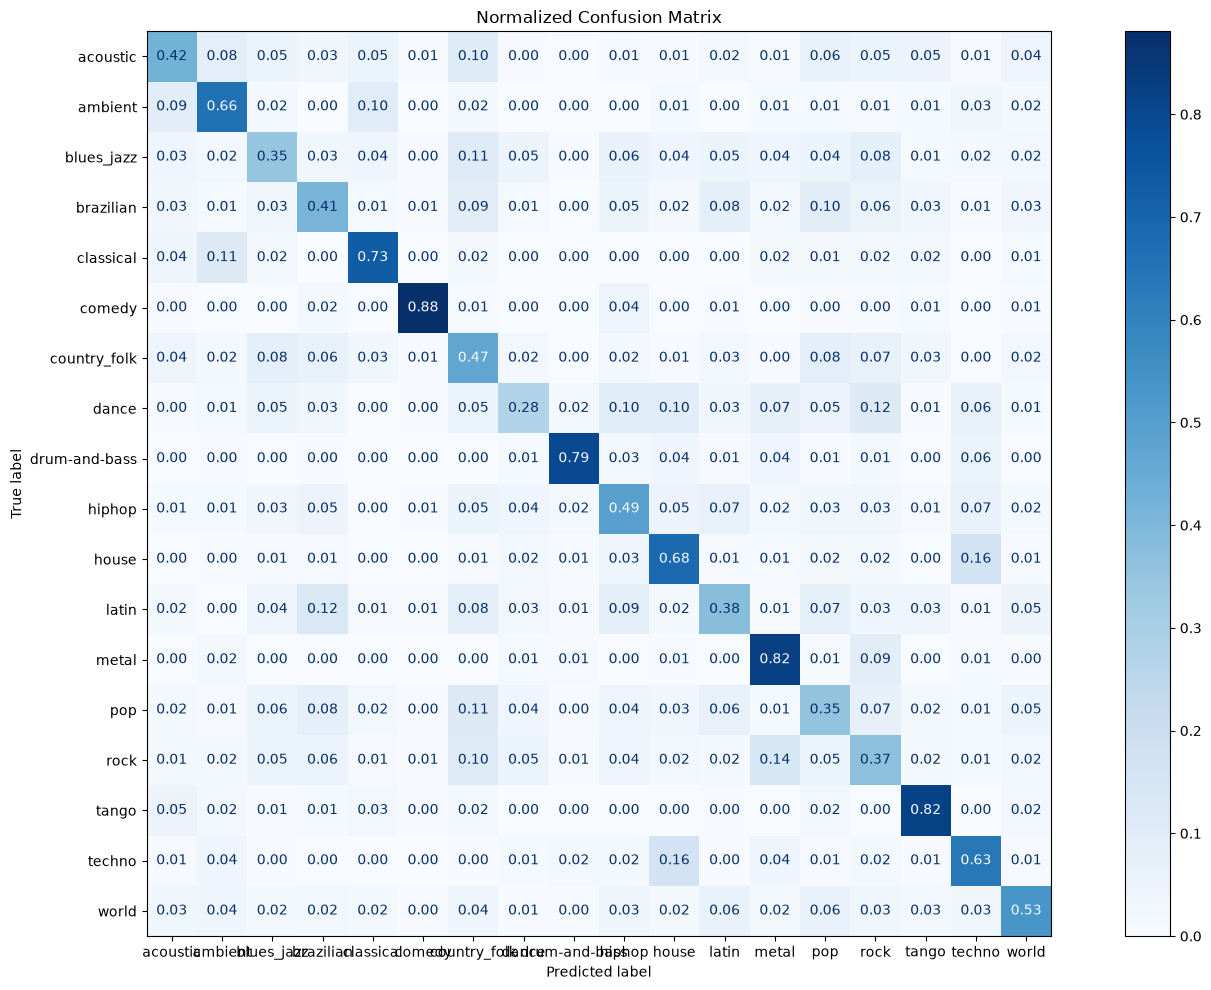

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    labels=range(len(y_encoder.classes_)),
    display_labels=y_encoder.classes_,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    ax=ax,

)

ax.set_title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Accuracy:", accuracy_score(y_test, pred))
print("F1:", f1_score(y_test, pred, average="macro"))

print(
    classification_report(
        y_test,
        pred,
        target_names=y_encoder.classes_,
        digits=3
    )
)


Accuracy: 0.47822990542482524
F1: 0.5073626963562413
               precision    recall  f1-score   support

     acoustic      0.468     0.420     0.443     11093
      ambient      0.576     0.662     0.616     11512
   blues_jazz      0.459     0.349     0.396     19723
    brazilian      0.446     0.414     0.430     17760
    classical      0.671     0.730     0.699     12330
       comedy      0.732     0.881     0.799      3178
 country_folk      0.374     0.470     0.416     18353
        dance      0.477     0.275     0.349     18480
drum-and-bass      0.521     0.794     0.629      2006
       hiphop      0.481     0.495     0.488     15572
        house      0.374     0.684     0.484      6484
        latin      0.377     0.378     0.377     11445
        metal      0.537     0.824     0.651     12839
          pop      0.397     0.352     0.373     19215
         rock      0.558     0.367     0.443     36655
        tango      0.365     0.816     0.505      2968
       tech

In [ ]:
pl.Config.set_tbl_rows(-1)
print(
    df.group_by("genre")
    .len()
    .sort("len")
)

shape: (18, 2)
┌───────────────┬────────┐
│ genre         ┆ len    │
│ ---           ┆ ---    │
│ str           ┆ u32    │
╞═══════════════╪════════╡
│ drum-and-bass ┆ 13378  │
│ tango         ┆ 19790  │
│ comedy        ┆ 21191  │
│ house         ┆ 43226  │
│ world         ┆ 53790  │
│ techno        ┆ 54774  │
│ acoustic      ┆ 73951  │
│ latin         ┆ 76301  │
│ ambient       ┆ 76744  │
│ classical     ┆ 82199  │
│ metal         ┆ 85591  │
│ hiphop        ┆ 103815 │
│ brazilian     ┆ 118399 │
│ country_folk  ┆ 122349 │
│ dance         ┆ 123196 │
│ pop           ┆ 128099 │
│ blues_jazz    ┆ 131485 │
│ rock          ┆ 244365 │
└───────────────┴────────┘
